# 01 · Start here

**The question of the project:** can a machine-learning model forecast stock returns well enough to improve a portfolio, and does a *robust* portfolio protect you when the model is wrong?

This notebook walks through the whole pipeline once, on the bundled data:

1. the data
2. the ML dataset: features and target
3. forecasts, scored as an ML problem
4. portfolios built from the forecasts, scored as a decision problem

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from robustfolio import (load_prices, returns_pct, HistoricalMean, SklearnForecaster, Strategy,
                         walk_forward_forecasts, forecast_scores, backtest, wealth)
from robustfolio.features import make_panel, FEATURES

plt.rcParams["figure.figsize"] = (10, 4)

## 1. The data

Daily prices of 10 large US stocks from 1990 to 2018 (adjusted for dividends and splits). Caveat: these are companies that are well known *today*, so the sample is biased towards winners (survivorship bias). Comparisons between strategies on the same stocks are still fair.

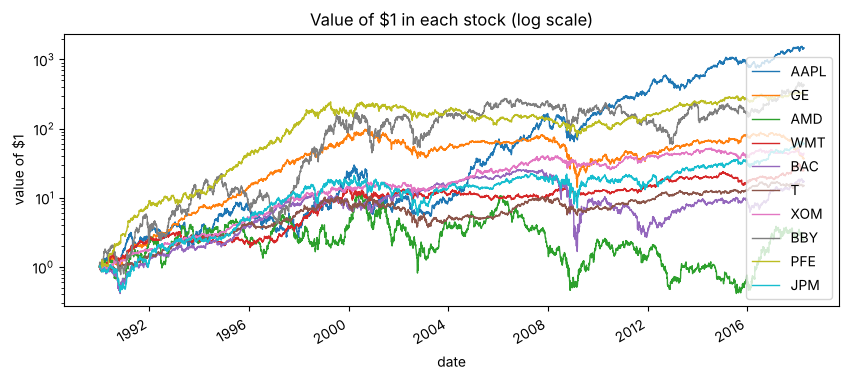

,mean daily return (%),daily volatility (%),worst day (%)
AAPL,0.144,2.870,-51.869
GE,0.067,1.816,-12.789
AMD,0.090,3.937,-37.931
WMT,0.059,1.656,-10.183
BAC,0.075,2.674,-28.969
T,0.051,1.613,-12.661
XOM,0.064,1.469,-13.953
BBY,0.139,3.271,-38.783
PFE,0.098,1.842,-11.146
JPM,0.087,2.414,-20.727


In [2]:
prices = load_prices()
returns = returns_pct(prices)          # daily returns in %
(prices / prices.iloc[0]).plot(logy=True, title="Value of $1 in each stock (log scale)", lw=1)
plt.ylabel("value of $1"); plt.show()

summary = pd.DataFrame({"mean daily return (%)": returns.mean(),
                        "daily volatility (%)": returns.std(),
                        "worst day (%)": returns.min()}).round(3)
summary

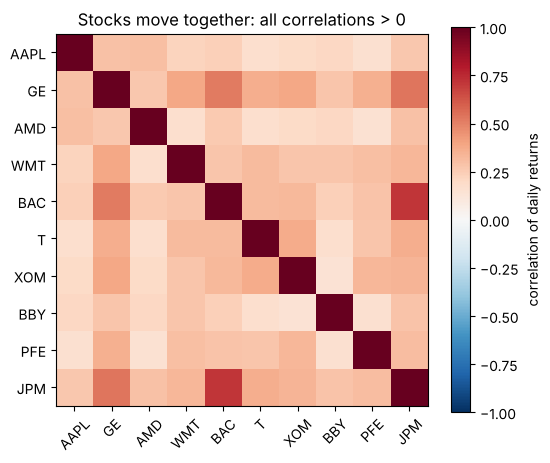

In [3]:
corr = returns.corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(10), corr.columns, rotation=45); ax.set_yticks(range(10), corr.columns)
fig.colorbar(im, label="correlation of daily returns"); ax.set_title("Stocks move together: all correlations > 0")
plt.show()

## 2. The ML dataset

One row per (month, stock). The **features** are computed only from the past (momentum over 1, 3 and 12 months, recent volatility); the **target** is the stock's average daily return over the *next* month. Note how weak the relation is: this is normal for returns, and it is the core difficulty of the project.

In [4]:
panel = make_panel(returns)
print(panel.shape)
panel.head()

(3280, 7)


,date,ticker,mom_1m,mom_3m,mom_12_1,vol_3m,target
0,1990-12-31,AAPL,0.783306,0.847158,0.218115,3.558218,1.089301
1,1990-12-31,GE,1.015793,0.298699,0.053176,2.420542,0.277785
2,1990-12-31,AMD,0.604443,-0.004927,-0.199838,4.845239,1.857638
3,1990-12-31,WMT,0.135000,0.201947,0.155682,2.400701,0.290251
4,1990-12-31,BAC,0.016295,0.302614,-0.179143,3.713179,0.944646


In [5]:
panel[FEATURES + ["target"]].corr()["target"].drop("target").round(3).to_frame("correlation with next month")

,correlation with next month
mom_1m,0.057
mom_3m,0.039
mom_12_1,0.026
vol_3m,0.100


## 3. Forecasts, scored as an ML problem

Walk-forward: every month, each forecaster sees only the past and predicts the next month for each stock.

- **historical mean**: the average of the last two years (what classic Markowitz uses);
- **ridge**: a linear model on the features, retrained every month on all the history so far.

Scores: *R² vs zero* (above 0 beats predicting "nothing happens"), *rank IC* (does it order the stocks correctly?), *hit rate* (is the sign right?).

In [6]:
START, STEP = 756, 21
ridge = SklearnForecaster(make_pipeline(StandardScaler(), Ridge(alpha=10.0)), name="ridge")
forecasts = {f.name: walk_forward_forecasts(f, returns, START, STEP) for f in [HistoricalMean(), ridge]}
pd.DataFrame({name: forecast_scores(f) for name, f in forecasts.items()}).round(3)

,historical mean,ridge
R2 vs zero,-0.014,0.003
rank IC,0.058,0.027
hit rate,0.566,0.589


## 4. Portfolios, scored as a decision problem

The same forecasts feed two portfolio rules:

- **Markowitz** trusts the forecast fully;
- **Robust mean-variance** lets an adversary reweight the past within a relative-entropy budget ρ, so it trusts the forecast only partly.

Minimum variance (no forecast at all) and equal weight are the references.

In [7]:
runs = [backtest(Strategy("Equal weight", "equal"), returns, start=START, step=STEP),
        backtest(Strategy("Minimum variance", "minvar"), returns, start=START, step=STEP)]
for f in forecasts.values():
    runs.append(backtest(Strategy("Markowitz", "markowitz"), returns, f, start=START, step=STEP))
    runs.append(backtest(Strategy("Robust", "robust_mv"), returns, f, start=START, step=STEP))

table = pd.DataFrame({r.name: r.metrics for r in runs}).T
table.style.format("{:.2f}")

,annual return,annual volatility,Sharpe (rf = 0),max drawdown,turnover / rebalance
Equal weight,0.18,0.22,0.84,-0.58,0.00
Minimum variance,0.15,0.17,0.89,-0.39,0.08
Markowitz + historical mean,0.19,0.22,0.92,-0.45,0.29
Robust + historical mean,0.17,0.18,0.96,-0.38,0.14
Markowitz + ridge,0.14,0.21,0.74,-0.46,0.57
Robust + ridge,0.15,0.17,0.89,-0.39,0.18


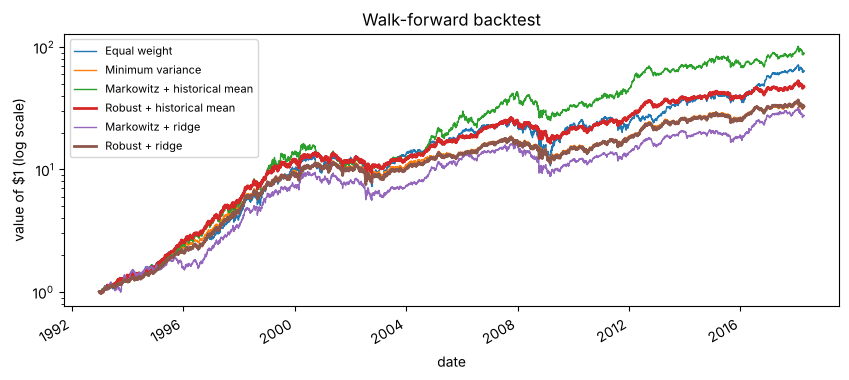

In [8]:
for r in runs:
    wealth(r).plot(logy=True, lw=2 if r.name.startswith("Robust") else 1)
plt.legend(fontsize=8); plt.ylabel("value of $1 (log scale)"); plt.title("Walk-forward backtest"); plt.show()

## What this shows, and what comes next

- The ridge forecast is slightly better than the historical mean by R², but worse at ordering the stocks; fed to Markowitz it **lowers** the Sharpe ratio and doubles the trading.
- The robust portfolio barely changes: it distrusts the forecast, so a bad forecast costs it little.

So the project is: **build forecasts good enough to help, and find how much a portfolio should trust them (ρ).** See the roadmap in the README.